In [ ]:
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

In [ ]:
!pip install -q kaggle tensorflow efficientnet
from google.colab import files
import os

KAGGLE_DIR = "/root/.kaggle"
KAGGLE_JSON_PATH = f"{KAGGLE_DIR}/kaggle.json"

if not os.path.exists(KAGGLE_JSON_PATH):
    print("kaggle.json not found. Please upload your kaggle.json file...")
    uploaded = files.upload()

    os.makedirs(KAGGLE_DIR, exist_ok=True)
    with open(KAGGLE_JSON_PATH, "w") as f:
        f.write(list(uploaded.values())[0].decode())

    os.chmod(KAGGLE_JSON_PATH, 600)
    print("✓ kaggle.json uploaded and configured")
else:
    print("✓ kaggle.json already exists — skipping upload")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 3.3 MB/s eta 0:00:00
kaggle.json not found. Please upload your kaggle.json file...


Saving kaggle.json to kaggle.json
✓ kaggle.json uploaded and configured


In [ ]:
DATASET_DIR = "/content/wildfire_data"
ZIP_FILE = "/content/wildfire-prediction-dataset.zip"

if not os.path.exists(DATASET_DIR):
    print("Dataset not found. Downloading from Kaggle...")

    !kaggle datasets download -d abdelghaniaaba/wildfire-prediction-dataset -p /content
    !unzip -q wildfire-prediction-dataset.zip -d /content/wildfire_data
    !rm wildfire-prediction-dataset.zip

    print("✓ Dataset downloaded and extracted")
else:
    print("✓ Dataset already exists — skipping download")

Dataset not found. Downloading from Kaggle...
Dataset URL: https://www.kaggle.com/datasets/abdelghaniaaba/wildfire-prediction-dataset
License(s): other
 99% 1.43G/1.45G [00:13<00:00, 39.0MB/s]
100% 1.45G/1.45G [00:13<00:00, 114MB/s] 
✓ Dataset downloaded and extracted


In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import layers, models
from keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 1e-5

print("GPU Available:", tf.config.list_physical_devices('GPU'))

GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    # vertical_flip=True,
    zoom_range=0.2,
    shear_range=0.2,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# Validation and test data - only rescaling
val_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Load datasets
train_generator = train_datagen.flow_from_directory(
    '/content/wildfire_data/train',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    seed=42
)

validation_generator = val_test_datagen.flow_from_directory(
    '/content/wildfire_data/valid',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    '/content/wildfire_data/test',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# Display class distribution
print("\n=== Dataset Information ===")
print(f"Training samples: {train_generator.samples}")
print(f"Validation samples: {validation_generator.samples}")
print(f"Test samples: {test_generator.samples}")
print(f"Class indices: {train_generator.class_indices}")

# Calculate class weights for balanced training
class_counts = {}
for class_name in train_generator.class_indices.keys():
    class_idx = train_generator.class_indices[class_name]
    class_counts[class_idx] = sum(train_generator.classes == class_idx)

total_samples = sum(class_counts.values())
class_weights = {
    cls: total_samples / (len(class_counts) * count)
    for cls, count in class_counts.items()
}
print(f"Class weights: {class_weights}")

Found 30250 images belonging to 2 classes.
Found 6300 images belonging to 2 classes.
Found 6300 images belonging to 2 classes.

=== Dataset Information ===
Training samples: 30250
Validation samples: 6300
Test samples: 6300
Class indices: {'nowildfire': 0, 'wildfire': 1}
Class weights: {0: np.float64(1.043103448275862), 1: np.float64(0.9603174603174603)}


In [ ]:
def build_model():
    # Load pre-trained EfficientNetB3
    base_model = EfficientNetB3(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    # Freeze base model initially
    base_model.trainable = False

    # Build model
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')
    ])

    return model, base_model

model, base_model = build_model()
model.summary()


43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb3 (Functional)     │ (None, 7, 7, 1536)     │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1536)           │         6,144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       786,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,711,280 (44.67 MB)

 Trainable params: 923,137 (3.52 MB)

 Non-trainable params: 10,788,143 (41.15 MB)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.AUC(name='auc')
    ]
)

In [ ]:
callbacks = [
    ModelCheckpoint(
        filepath='/content/drive/MyDrive/best_wildfire_model.h5',
        monitor='val_auc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

In [ ]:
print("\n=== Phase 1: Training with frozen base model ===")
history_phase1 = model.fit(
    train_generator,
    epochs=10,
    validation_data=validation_generator,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)


=== Phase 1: Training with frozen base model ===


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 0s 528ms/step - accuracy: 0.7307 - auc: 0.7990 - loss: 0.5619 - precision: 0.7409 - recall: 0.7359
Epoch 1: val_auc improved from -inf to 0.96928, saving model to /content/drive/MyDrive/best_wildfire_model.h5


946/946 ━━━━━━━━━━━━━━━━━━━━ 596s 575ms/step - accuracy: 0.7308 - auc: 0.7991 - loss: 0.5618 - precision: 0.7410 - recall: 0.7360 - val_accuracy: 0.8946 - val_auc: 0.9693 - val_loss: 0.2720 - val_precision: 0.9551 - val_recall: 0.8491 - learning_rate: 1.0000e-05
Epoch 2/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step - accuracy: 0.8878 - auc: 0.9513 - loss: 0.2833 - precision: 0.8873 - recall: 0.8991
Epoch 2: val_auc improved from 0.96928 to 0.97731, saving model to /content/drive/MyDrive/best_wildfire_model.h5


946/946 ━━━━━━━━━━━━━━━━━━━━ 481s 509ms/step - accuracy: 0.8878 - auc: 0.9513 - loss: 0.2833 - precision: 0.8873 - recall: 0.8991 - val_accuracy: 0.9129 - val_auc: 0.9773 - val_loss: 0.2308 - val_precision: 0.9645 - val_recall: 0.8744 - learning_rate: 1.0000e-05
Epoch 3/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step - accuracy: 0.9012 - auc: 0.9613 - loss: 0.2551 - precision: 0.9047 - recall: 0.9066
Epoch 3: val_auc improved from 0.97731 to 0.98084, saving model to /content/drive/MyDrive/best_wildfire_model.h5


...

946/946 ━━━━━━━━━━━━━━━━━━━━ 476s 503ms/step - accuracy: 0.9139 - auc: 0.9694 - loss: 0.2247 - precision: 0.9133 - recall: 0.9217 - val_accuracy: 0.9375 - val_auc: 0.9848 - val_loss: 0.1691 - val_precision: 0.9667 - val_recall: 0.9184 - learning_rate: 1.0000e-05
Epoch 7/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step - accuracy: 0.9198 - auc: 0.9722 - loss: 0.2136 - precision: 0.9204 - recall: 0.9261
Epoch 7: val_auc improved from 0.98483 to 0.98610, saving model to /content/drive/MyDrive/best_wildfire_model.h5


946/946 ━━━━━━━━━━━━━━━━━━━━ 485s 513ms/step - accuracy: 0.9198 - auc: 0.9722 - loss: 0.2136 - precision: 0.9204 - recall: 0.9261 - val_accuracy: 0.9384 - val_auc: 0.9861 - val_loss: 0.1639 - val_precision: 0.9682 - val_recall: 0.9187 - learning_rate: 1.0000e-05
Epoch 8/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 0s 481ms/step - accuracy: 0.9221 - auc: 0.9735 - loss: 0.2069 - precision: 0.9237 - recall: 0.9277
Epoch 8: val_auc improved from 0.98610 to 0.98681, saving model to /content/drive/MyDrive/best_wildfire_model.h5


946/946 ━━━━━━━━━━━━━━━━━━━━ 472s 499ms/step - accuracy: 0.9221 - auc: 0.9735 - loss: 0.2069 - precision: 0.9237 - recall: 0.9277 - val_accuracy: 0.9443 - val_auc: 0.9868 - val_loss: 0.1525 - val_precision: 0.9666 - val_recall: 0.9313 - learning_rate: 1.0000e-05
Epoch 9/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step - accuracy: 0.9220 - auc: 0.9738 - loss: 0.2064 - precision: 0.9232 - recall: 0.9269
Epoch 9: val_auc improved from 0.98681 to 0.98714, saving model to /content/drive/MyDrive/best_wildfire_model.h5


946/946 ━━━━━━━━━━━━━━━━━━━━ 483s 511ms/step - accuracy: 0.9220 - auc: 0.9738 - loss: 0.2064 - precision: 0.9232 - recall: 0.9269 - val_accuracy: 0.9440 - val_auc: 0.9871 - val_loss: 0.1520 - val_precision: 0.9680 - val_recall: 0.9293 - learning_rate: 1.0000e-05
Epoch 10/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.9257 - auc: 0.9770 - loss: 0.1927 - precision: 0.9256 - recall: 0.9317
Epoch 10: val_auc improved from 0.98714 to 0.98755, saving model to /content/drive/MyDrive/best_wildfire_model.h5


946/946 ━━━━━━━━━━━━━━━━━━━━ 492s 521ms/step - accuracy: 0.9257 - auc: 0.9770 - loss: 0.1927 - precision: 0.9256 - recall: 0.9317 - val_accuracy: 0.9432 - val_auc: 0.9876 - val_loss: 0.1538 - val_precision: 0.9702 - val_recall: 0.9256 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 9.


In [ ]:
print("\n=== Phase 2: Fine-tuning with unfrozen layers ===")

# Unfreeze the last 50 layers of base model
base_model.trainable = True
for layer in base_model.layers[:-50]:
    layer.trainable = False

# Recompile with lower learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE/10),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.AUC(name='auc')
    ]
)

# Continue training
history_phase2 = model.fit(
    train_generator,
    epochs=EPOCHS,
    initial_epoch=history_phase1.epoch[-1],
    validation_data=validation_generator,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

# Combine histories
history = {
    key: history_phase1.history[key] + history_phase2.history[key]
    for key in history_phase1.history.keys()
}



=== Phase 2: Fine-tuning with unfrozen layers ===
Epoch 10/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 0s 509ms/step - accuracy: 0.8597 - auc: 0.9332 - loss: 0.3329 - precision: 0.8698 - recall: 0.8579
Epoch 10: val_auc did not improve from 0.98755
946/946 ━━━━━━━━━━━━━━━━━━━━ 567s 544ms/step - accuracy: 0.8597 - auc: 0.9332 - loss: 0.3329 - precision: 0.8698 - recall: 0.8579 - val_accuracy: 0.8925 - val_auc: 0.9639 - val_loss: 0.2718 - val_precision: 0.9354 - val_recall: 0.8652 - learning_rate: 1.0000e-06
Epoch 11/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 0s 484ms/step - accuracy: 0.8850 - auc: 0.9520 - loss: 0.2815 - precision: 0.8865 - recall: 0.8922
Epoch 11: val_auc did not improve from 0.98755
946/946 ━━━━━━━━━━━━━━━━━━━━ 472s 499ms/step - accuracy: 0.8850 - auc: 0.9520 - loss: 0.2815 - precision: 0.8865 - recall: 0.8922 - val_accuracy: 0.9048 - val_auc: 0.9705 - val_loss: 0.2489 - val_precision: 0.9500 - val_recall: 0.8736 - learning_rate: 1.0000e-06
Epoch 12/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms

In [ ]:
# model.load_weights("best_wildfire_model.h5")
# print("✓ Best Phase-1 weights loaded")

In [ ]:
print("\n=== Evaluating on Test Set ===")
test_loss, test_acc, test_precision, test_recall, test_auc = model.evaluate(test_generator)

print(f"\nTest Results:")
print(f"Loss: {test_loss:.4f}")
print(f"Accuracy: {test_acc:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"AUC: {test_auc:.4f}")
print(f"F1-Score: {2 * (test_precision * test_recall) / (test_precision + test_recall):.4f}")


=== Evaluating on Test Set ===
197/197 ━━━━━━━━━━━━━━━━━━━━ 16s 80ms/step - accuracy: 0.9517 - auc: 0.5473 - loss: 0.1341 - precision: 0.4945 - recall: 0.5069

Test Results:
Loss: 0.1787
Accuracy: 0.9351
Precision: 0.9677
Recall: 0.9129
AUC: 0.9853
F1-Score: 0.9395


197/197 ━━━━━━━━━━━━━━━━━━━━ 41s 159ms/step

=== Classification Report ===
              precision    recall  f1-score   support

  nowildfire       0.90      0.96      0.93      2820
    wildfire       0.97      0.91      0.94      3480

    accuracy                           0.94      6300
   macro avg       0.93      0.94      0.93      6300
weighted avg       0.94      0.94      0.94      6300



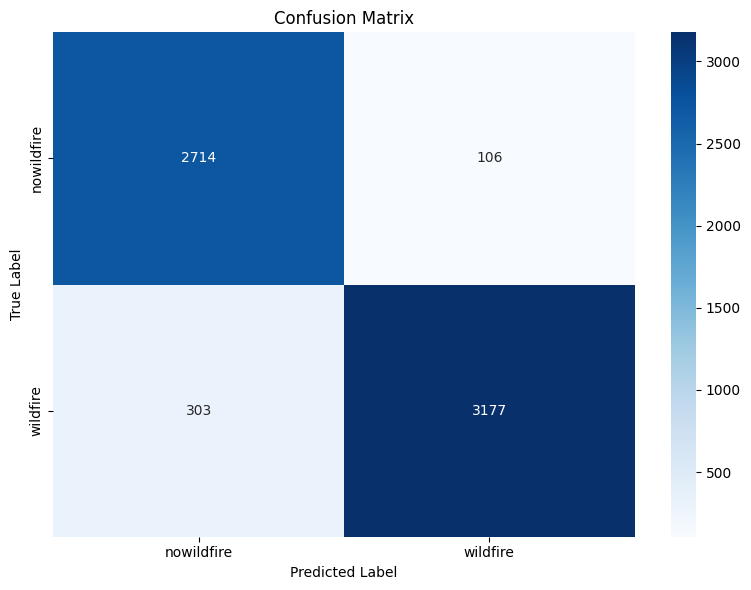

In [ ]:
test_generator.reset()
y_pred_prob = model.predict(test_generator, verbose=1)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
y_true = test_generator.classes

# Classification report
print("\n=== Classification Report ===")
class_names = list(test_generator.class_indices.keys())
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

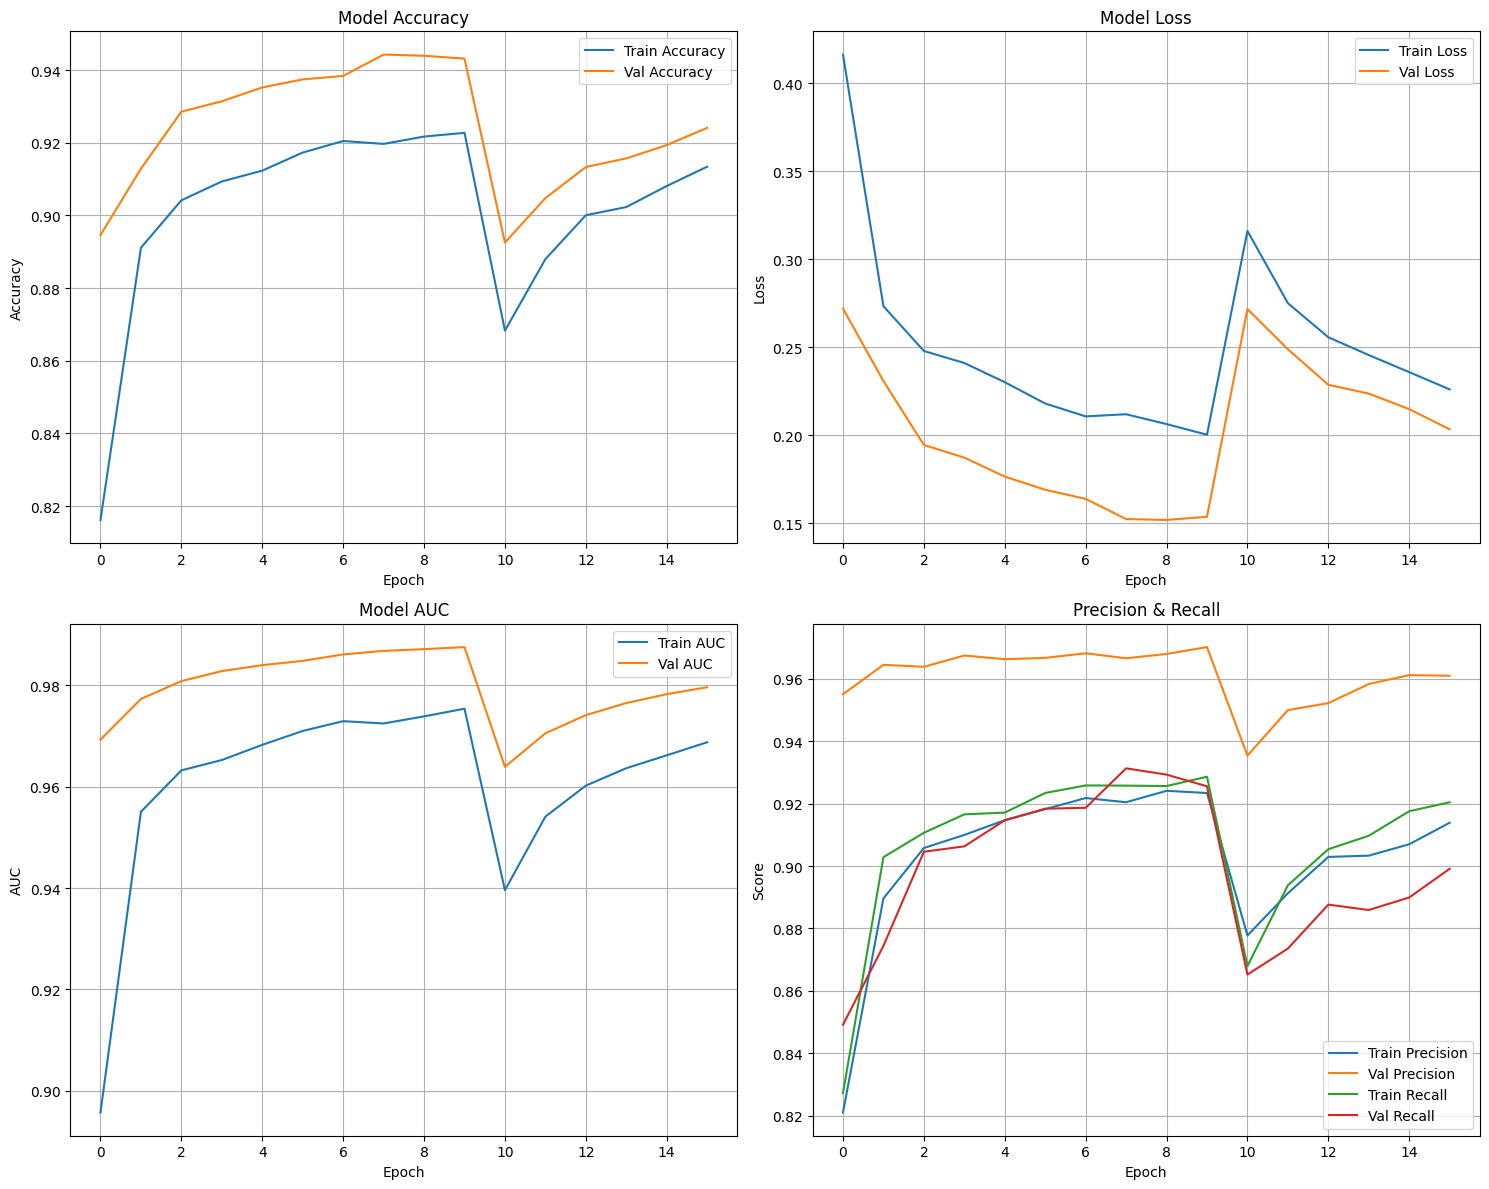

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Accuracy
axes[0, 0].plot(history['accuracy'], label='Train Accuracy')
axes[0, 0].plot(history['val_accuracy'], label='Val Accuracy')
axes[0, 0].set_title('Model Accuracy')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].legend()
axes[0, 0].grid(True)

# Loss
axes[0, 1].plot(history['loss'], label='Train Loss')
axes[0, 1].plot(history['val_loss'], label='Val Loss')
axes[0, 1].set_title('Model Loss')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()
axes[0, 1].grid(True)

# AUC
axes[1, 0].plot(history['auc'], label='Train AUC')
axes[1, 0].plot(history['val_auc'], label='Val AUC')
axes[1, 0].set_title('Model AUC')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('AUC')
axes[1, 0].legend()
axes[1, 0].grid(True)

# Precision & Recall
axes[1, 1].plot(history['precision'], label='Train Precision')
axes[1, 1].plot(history['val_precision'], label='Val Precision')
axes[1, 1].plot(history['recall'], label='Train Recall')
axes[1, 1].plot(history['val_recall'], label='Val Recall')
axes[1, 1].set_title('Precision & Recall')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Score')
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig('training_history.png', dpi=300, bbox_inches='tight')
plt.show()


=== Visualizing Predictions ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step


/tmp/ipython-input-577022630.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  pred_label = class_names[int(predictions[i] > 0.5)]


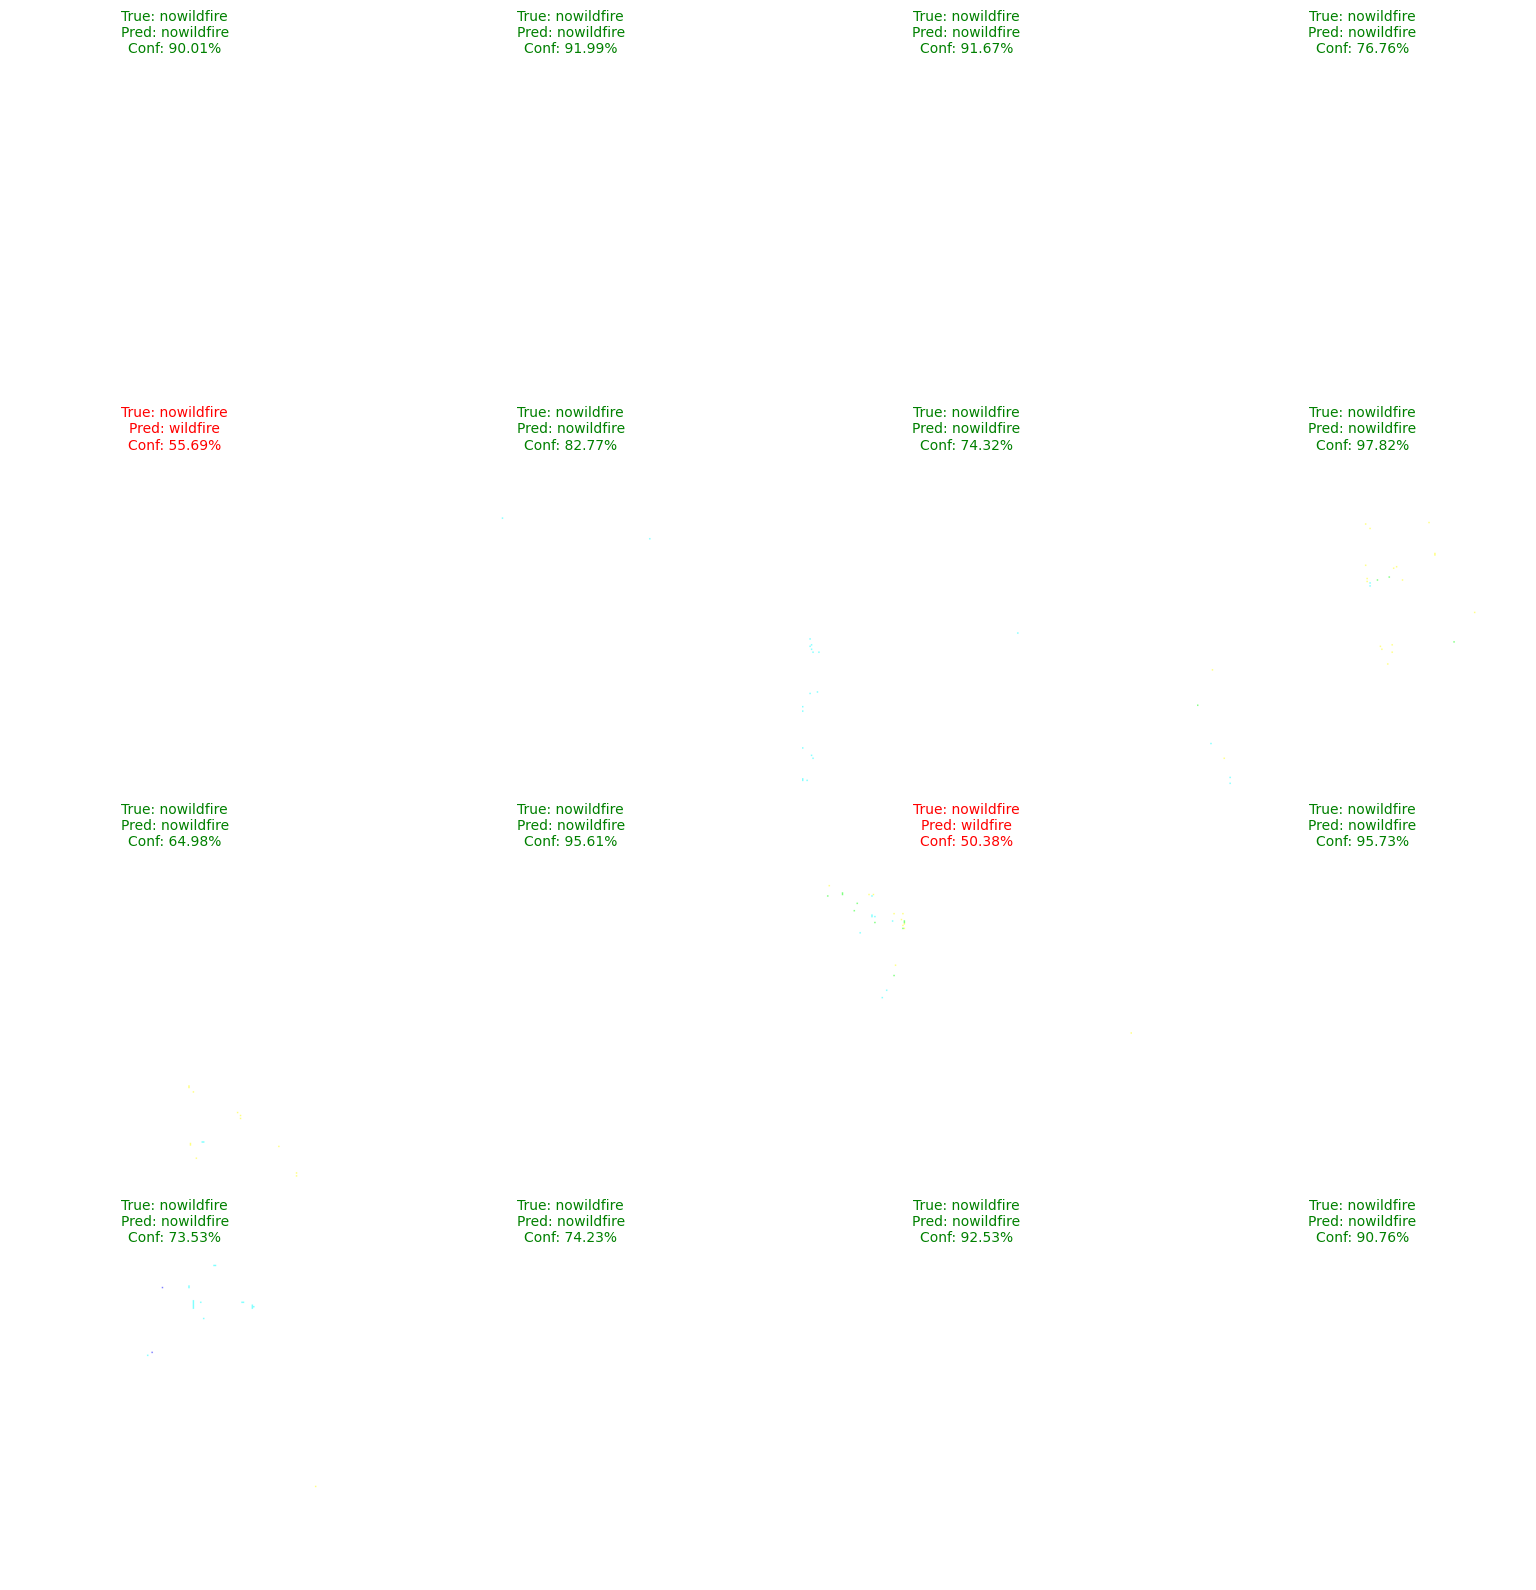

In [ ]:
def visualize_predictions(generator, model, num_images=16):
    generator.reset()
    x_batch, y_batch = next(generator)
    predictions = model.predict(x_batch[:num_images])

    fig, axes = plt.subplots(4, 4, figsize=(16, 16))
    axes = axes.flatten()

    for i in range(num_images):
        img = (x_batch[i] + 1) / 2
        axes[i].imshow(img)

        true_label = class_names[int(y_batch[i])]
        pred_label = class_names[int(predictions[i] > 0.5)]
        confidence = predictions[i][0] if predictions[i] > 0.5 else 1 - predictions[i][0]

        color = 'green' if true_label == pred_label else 'red'
        axes[i].set_title(f'True: {true_label}\nPred: {pred_label}\nConf: {confidence:.2%}',
                         color=color, fontsize=10)
        axes[i].axis('off')

    plt.tight_layout()
    plt.savefig('predictions_visualization.png', dpi=300, bbox_inches='tight')
    plt.show()

print("\n=== Visualizing Predictions ===")
visualize_predictions(test_generator, model)

In [ ]:
model.save('wildfire_prediction_model_final.h5')
print("\n✓ Model saved as 'wildfire_prediction_model_final.h5'")

# Save model in TensorFlow SavedModel format
model.save("/content/drive/MyDrive/wildfire_model_final.keras")
model.save("/content/drive/MyDrive/wildfire_prediction_model_final.h5")
print("✓ Model saved in SavedModel format")

print("\n=== Training Complete! ===")
print(f"Best model saved as 'best_wildfire_model.h5'")
print(f"Final test accuracy: {test_acc:.4f}")
print(f"Final test AUC: {test_auc:.4f}")


✓ Model saved as 'wildfire_prediction_model_final.h5'


✓ Model saved in SavedModel format

=== Training Complete! ===
Best model saved as 'best_wildfire_model.h5'
Final test accuracy: 0.9351
Final test AUC: 0.9853


In [ ]:
print(train_generator.class_indices)


{'nowildfire': 0, 'wildfire': 1}


In [ ]:
import tensorflow as tf
print(tf.__version__)


2.19.0
